# Imports

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
sns.set_theme(style="darkgrid")

In [3]:
df = pd.read_csv("Data/Raw/tiktok_dataset.csv")


# Basic Data inspection

| Column name | Type | Description |
| :--- | :--- | :--- |
| **#** | int | TikTok assigned number for video with claim/opinion. |
| **claim_status** | obj | Whether the published video has been identified as an “opinion” or a “claim.” In this dataset, an “opinion” refers to an individual’s or group’s personal belief or thought. A “claim” refers to information that is either unsourced or from an unverified source. |
| **video_id** | int | Random identifying number assigned to video upon publication on TikTok. |
| **video_duration_sec** | int | How long the published video is measured in seconds. |
| **video_transcription_text** | obj | Transcribed text of the words spoken in the published video. |
| **verified_status** | obj | Indicates the status of the TikTok user who published the video in terms of their verification, either “verified” or “not verified.” |
| **author_ban_status** | obj | Indicates the status of the TikTok user who published the video in terms of their permissions: “active,” “under scrutiny,” or “banned.” |
| **video_view_count** | float | The total number of times the published video has been viewed. |
| **video_like_count** | float | The total number of times the published video has been liked by other users. |
| **video_share_count** | float | The total number of times the published video has been shared by other users. |
| **video_download_count** | float | The total number of times the published video has been downloaded by other users. |
| **video_comment_count** | float | The total number of comments on the published video. |

In [4]:
df.sample(5)

,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
2731,2732,claim,1983736694,20,a friend read in a discussion board a claim t...,not verified,active,822704.0,100348.0,38746.0,669.0,442.0
10592,10593,opinion,2100695287,45,my friends understand that most car horns honk...,verified,active,5290.0,423.0,100.0,8.0,2.0
15062,15063,opinion,4465120049,30,my family's understanding is that there are mo...,verified,active,4133.0,677.0,1.0,16.0,0.0
11276,11277,opinion,2621993446,30,my view is that the japanese word ‘karaoke’ co...,not verified,active,2304.0,939.0,286.0,20.0,3.0
483,484,claim,8173056093,31,the news mentioned someone discovered that the...,not verified,active,129725.0,80331.0,20695.0,797.0,375.0


In [5]:
df.info();

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19382 entries, 0 to 19381
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   #                         19382 non-null  int64  
 1   claim_status              19084 non-null  object 
 2   video_id                  19382 non-null  int64  
 3   video_duration_sec        19382 non-null  int64  
 4   video_transcription_text  19084 non-null  object 
 5   verified_status           19382 non-null  object 
 6   author_ban_status         19382 non-null  object 
 7   video_view_count          19084 non-null  float64
 8   video_like_count          19084 non-null  float64
 9   video_share_count         19084 non-null  float64
 10  video_download_count      19084 non-null  float64
 11  video_comment_count       19084 non-null  float64
dtypes: float64(5), int64(3), object(4)
memory usage: 1.8+ MB


In [6]:
df.isnull().sum().sort_values(ascending=False)

claim_status                298
video_share_count           298
video_view_count            298
video_transcription_text    298
video_download_count        298
video_comment_count         298
video_like_count            298
#                             0
video_duration_sec            0
video_id                      0
author_ban_status             0
verified_status               0
dtype: int64

In [7]:
df.describe()

,#,video_id,video_duration_sec,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
count,19382.000000,1.938200e+04,19382.000000,19084.000000,19084.000000,19084.000000,19084.000000,19084.000000
mean,9691.500000,5.627454e+09,32.421732,254708.558688,84304.636030,16735.248323,1049.429627,349.312146
std,5595.245794,2.536440e+09,16.229967,322893.280814,133420.546814,32036.174350,2004.299894,799.638865
min,1.000000,1.234959e+09,5.000000,20.000000,0.000000,0.000000,0.000000,0.000000
25%,4846.250000,3.430417e+09,18.000000,4942.500000,810.750000,115.000000,7.000000,1.000000
50%,9691.500000,5.618664e+09,32.000000,9954.500000,3403.500000,717.000000,46.000000,9.000000
75%,14536.750000,7.843960e+09,47.000000,504327.000000,125020.000000,18222.000000,1156.250000,292.000000
max,19382.000000,9.999873e+09,60.000000,999817.000000,657830.000000,256130.000000,14994.000000,9599.000000


In [8]:
df.claim_status.value_counts()

claim_status
claim      9608
opinion    9476
Name: count, dtype: int64

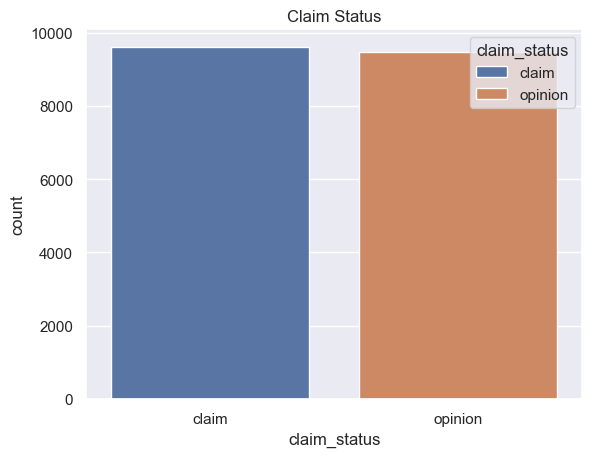

In [9]:
sns.countplot(x="claim_status", data=df, hue="claim_status"), plt.title("Claim Status");

In [10]:
# av view count of claims vs opinions

claims_mask = df["claim_status"] == "claim"
opinions_mask = df["claim_status"] == "opinion"

print(
    "claims: \naverage: ",
    df[claims_mask]["video_view_count"].mean(),
    "median: ",
    df[claims_mask]["video_view_count"].median(),
    "\n",
)
print(
    "opinions: \naverage:",
    df[opinions_mask]["video_view_count"].mean(),
    "median: ",
    df[opinions_mask]["video_view_count"].median(),
)


claims: 
average:  501029.4527477102 median:  501555.0 

opinions: 
average: 4956.43224989447 median:  4953.0


In [11]:
# Get counts for each group combination of claim status and author ban status

df.groupby(["claim_status", "author_ban_status"]).count()[["#"]]

#
claim_status author_ban_status      
claim        active             6566
             banned             1439
             under review       1603
opinion      active             8817
             banned              196
             under review        463

There are many more claim videos with banned authors than there are opinion videos with banned authors. This could mean a number of things, including the possibilities that:
* Claim videos are more strictly policed than opinion videos
* Authors must comply with a stricter set of rules if they post a claim than if they post an opinion

In [12]:
df.groupby("author_ban_status").agg(
    {
        "video_view_count": ["mean", "median"],
        "video_like_count": ["mean", "median"],
        "video_share_count": ["mean", "median"],
    }
)

video_view_count           video_like_count            \
                              mean    median             mean    median   
author_ban_status                                                         
active               215927.039524    8616.0     71036.533836    2222.0   
banned               445845.439144  448201.0    153017.236697  105573.0   
under review         392204.836399  365245.5    128718.050339   71204.5   

                  video_share_count           
                               mean   median  
author_ban_status                             
active                 14111.466164    437.0  
banned                 29998.942508  14468.0  
under review           25774.696999   9444.0

* Banned authors and those under review get far more views, likes, and shares than active authors.
* In most groups, the mean is much greater than the median, which indicates that there are some videos with very high engagement counts.

In [13]:
# What's the median video share count of each author ban status?

df.groupby(["author_ban_status"]).median(numeric_only=True)[["video_share_count"]]

,video_share_count
author_ban_status,
active,437.0
banned,14468.0
under review,9444.0


Banned authors have a median share count that's 33 times the median share count of active authors

In [14]:
# Create a likes_per_view column
df["likes_per_view"] = df["video_like_count"] / df["video_view_count"]

# Create a comments_per_view column
df["comments_per_view"] = df["video_comment_count"] / df["video_view_count"]

# Create a shares_per_view column
df["shares_per_view"] = df["video_share_count"] / df["video_view_count"]

In [15]:
df.groupby(["claim_status", "author_ban_status"]).agg(
    {
        "likes_per_view": ["count", "mean", "median"],
        "comments_per_view": ["count", "mean", "median"],
        "shares_per_view": ["count", "mean", "median"],
    }
)

likes_per_view                      \
                                        count      mean    median   
claim_status author_ban_status                                      
claim        active                      6566  0.329542  0.326538   
             banned                      1439  0.345071  0.358909   
             under review                1603  0.327997  0.320867   
opinion      active                      8817  0.219744  0.218330   
             banned                       196  0.206868  0.198483   
             under review                 463  0.226394  0.228051   

                               comments_per_view                      \
                                           count      mean    median   
claim_status author_ban_status                                         
claim        active                         6566  0.001393  0.000776   
             banned                         1439  0.001377  0.000746   
             under review                   1603  0.001367  0.000789   
opinion      active                         8817  0.000517  0.000252   
             banned                          196  0.000434  0.000193   
             under review                    463  0.000536  0.000293   

                               shares_per_view                      
                                         count      mean    median  
claim_status author_ban_status                                      
claim        active                       6566  0.065456  0.049279  
             banned                       1439  0.067893  0.051606  
             under review                 1603  0.065733  0.049967  
opinion      active                       8817  0.043729  0.032405  
             banned                        196  0.040531  0.030728  
             under review                  463  0.044472  0.035027

We know that videos by banned authors and those under review tend to get far more views, likes, and shares than videos by non-banned authors. However, *when a video does get viewed*, its engagement rate is less related to author ban status and more related to its claim status.

Also, we know that claim videos have a higher view rate than opinion videos, but this tells us that claim videos also have a higher rate of likes on average, so they are more favorably received as well. Furthermore, they receive more engagement via comments and shares than opinion videos.

Note that for claim videos, banned authors have slightly higher likes/view and shares/view rates than active authors or those under review. However, for opinion videos, active authors and those under review both get higher engagement rates than banned authors in all categories.

# Univariate Analysis

### video_duration_sec

In [30]:
df.video_duration_sec.describe()

count    19382.000000
mean        32.421732
std         16.229967
min          5.000000
25%         18.000000
50%         32.000000
75%         47.000000
max         60.000000
Name: video_duration_sec, dtype: float64

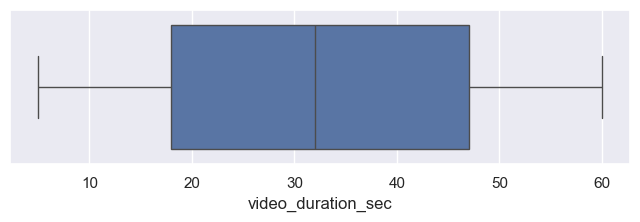

In [ ]:
plt.figure(figsize=(8, 2))
sns.boxplot(x=df["video_duration_sec"]);

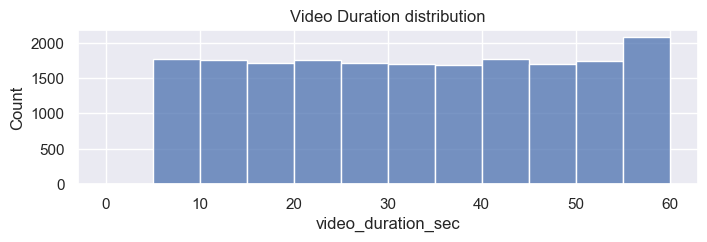

In [26]:
plt.figure(figsize=(8, 2))
plt.title("Video Duration distribution")
sns.histplot(x=df["video_duration_sec"], bins=range(0, 61, 5));

All videos are 5-60 seconds in length, and the distribution is uniform.

---

### video_view_count

In [38]:
df.video_view_count.describe()

count     19084.000000
mean     254708.558688
std      322893.280814
min          20.000000
25%        4942.500000
50%        9954.500000
75%      504327.000000
max      999817.000000
Name: video_view_count, dtype: float64

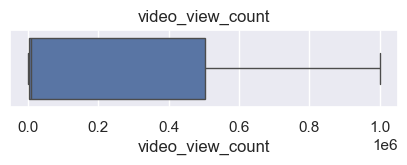

In [ ]:
plt.figure(figsize=(5, 1))
plt.title("video_view_count")
sns.boxplot(x=df["video_view_count"]);

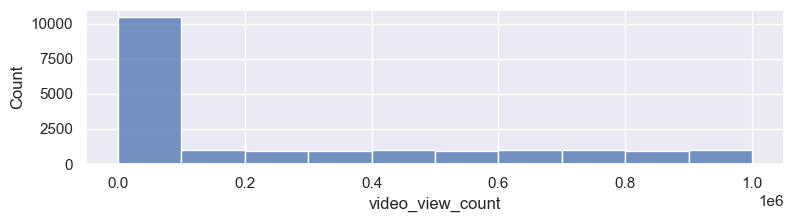

In [ ]:
plt.figure(figsize=(9, 2))
sns.histplot(
    data=df,
    x="video_view_count",
    bins=range(0, 10**6 + 1, 10**5),
);

This variable has a very uneven distribution, with more than half the videos receiving fewer than 100,000 views. Distribution of view counts > 100,000 views is uniform.

---
### video_like_count

In [63]:
df.video_like_count.describe()

count     19084.000000
mean      84304.636030
std      133420.546814
min           0.000000
25%         810.750000
50%        3403.500000
75%      125020.000000
max      657830.000000
Name: video_like_count, dtype: float64

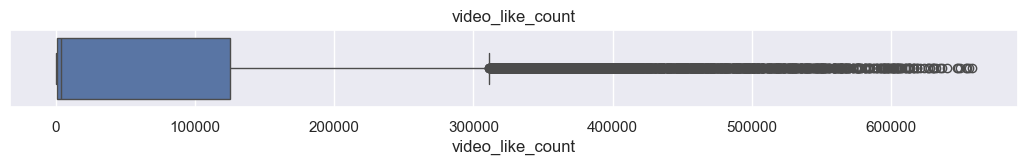

In [ ]:
plt.figure(figsize=(13, 1))
plt.title("video_like_count")
sns.boxplot(x=df["video_like_count"]);

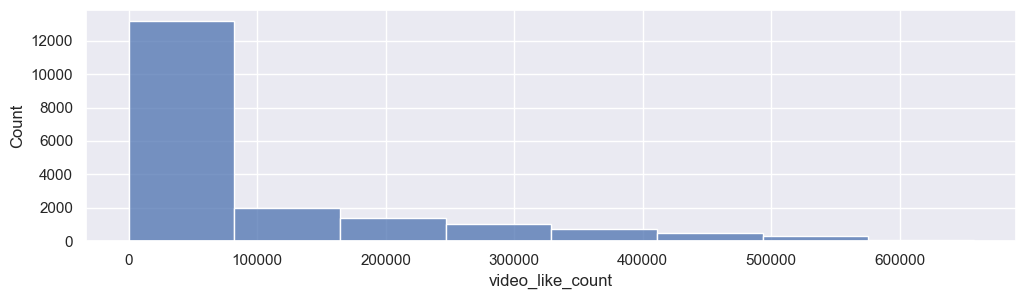

In [56]:
plt.figure(figsize=(12, 3))
sns.histplot(data=df, x="video_like_count", bins=8);

Similar to view count, there are far more videos with < 100,000 likes than there are videos with more. However, in this case, there is more of a taper, as the data skews right, with many videos at the upper extremity of like count.

---
### video_comment_count

In [64]:
df.video_comment_count.describe()

count    19084.000000
mean       349.312146
std        799.638865
min          0.000000
25%          1.000000
50%          9.000000
75%        292.000000
max       9599.000000
Name: video_comment_count, dtype: float64

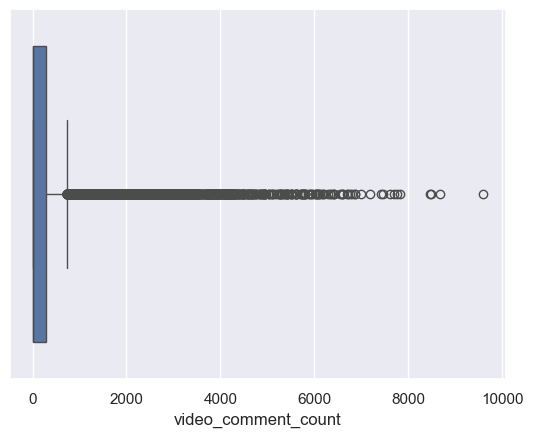

In [ ]:
sns.boxplot(x=df["video_comment_count"]);

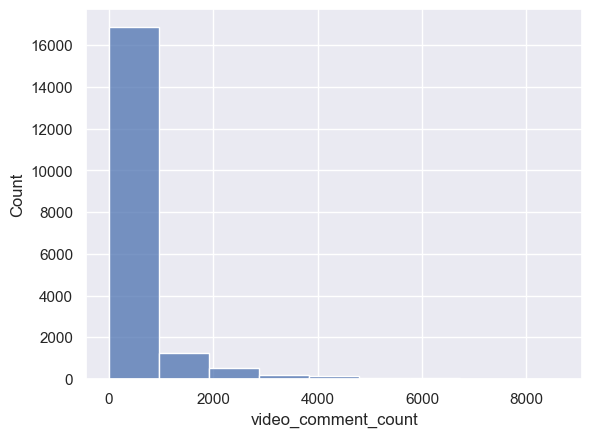

In [ ]:
sns.histplot(data=df, x="video_comment_count", bins=range(0, 9600, 960));

Again, the vast majority of videos are grouped at the bottom of the range of values for video comment count. Most videos have fewer than 100 comments. The distribution is very right-skewed.

---
### video_share_count

In [68]:
df.video_share_count.describe()

count     19084.000000
mean      16735.248323
std       32036.174350
min           0.000000
25%         115.000000
50%         717.000000
75%       18222.000000
max      256130.000000
Name: video_share_count, dtype: float64

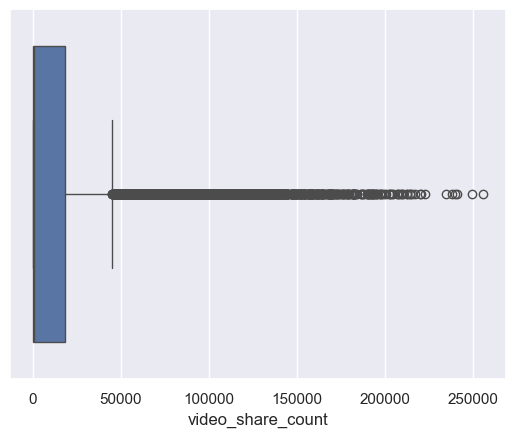

In [ ]:
sns.boxplot(x=df["video_share_count"]);

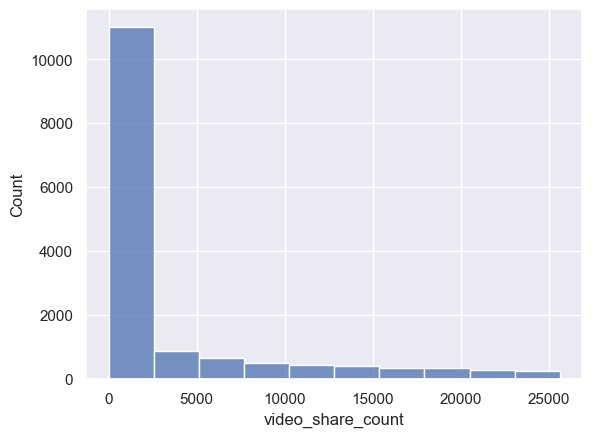

In [ ]:
sns.histplot(data=df, x=df["video_share_count"], bins=range(0, 25631, 2563));

The overwhelming majority of videos had fewer than 10,000 shares. The distribution is very skewed to the right.

---
### video_download_count

In [74]:
df.video_download_count.describe()

count    19084.000000
mean      1049.429627
std       2004.299894
min          0.000000
25%          7.000000
50%         46.000000
75%       1156.250000
max      14994.000000
Name: video_download_count, dtype: float64

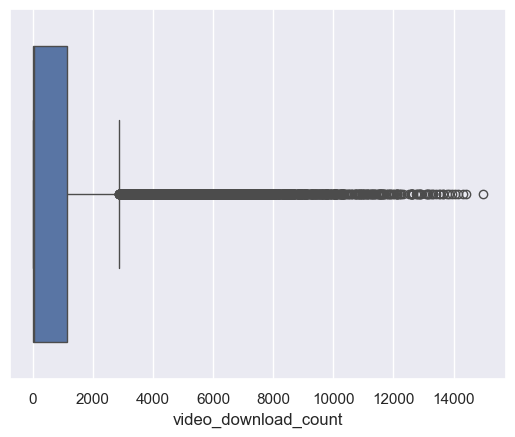

In [ ]:
sns.boxplot(x=df["video_download_count"]);

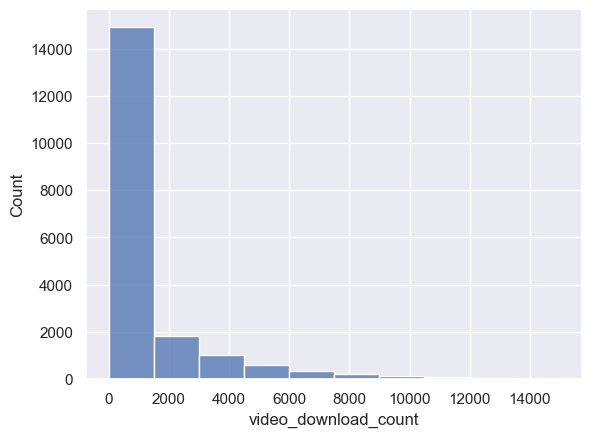

In [ ]:
sns.histplot(data=df, x=df["video_download_count"], bins=range(0, 14995, 1499));

The majority of videos were downloaded fewer than 500 times, but some were downloaded over 12,000 times. Again, the data is very skewed to the right.


---

### Claim status by verification status

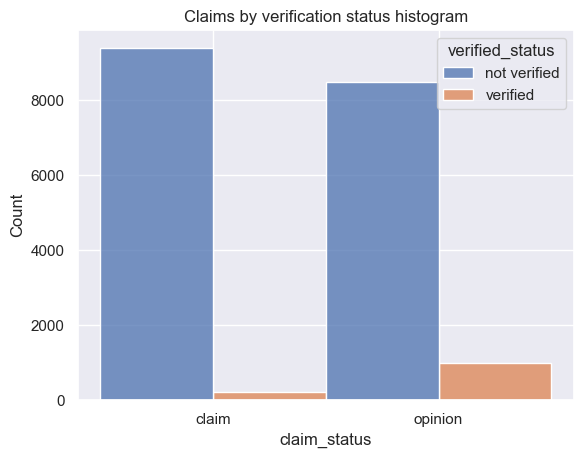

In [ ]:
(
    sns.histplot(data=df, x="claim_status", hue="verified_status", multiple="dodge"),
    plt.title("Claims by verification status histogram"),
);

There are far fewer verified users than unverified users, but if a user is verified, they are much more likely to post opinions.

---
### Claim status by author ban status

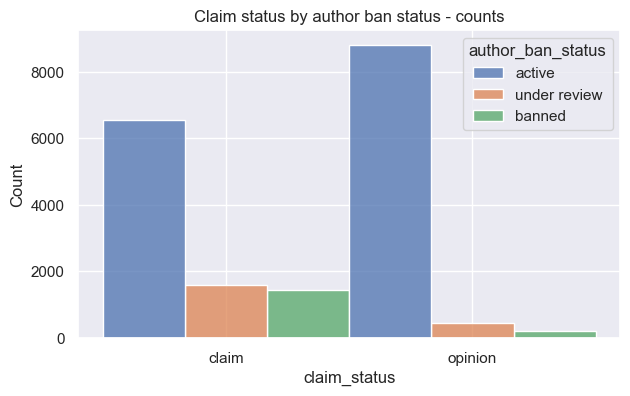

In [ ]:
fig = plt.figure(figsize=(7, 4))
sns.histplot(
    df,
    x="claim_status",
    hue="author_ban_status",
    multiple="dodge",
    hue_order=["active", "under review", "banned"],
)
plt.title("Claim status by author ban status - counts");

For both claims and opinions, there are many more active authors than banned authors or authors under review; however, the proportion of active authors is far greater for opinion videos than for claim videos. Again, it seems that authors who post claim videos are more likely to come under review and/or get banned.

---
### Median view counts by ban status


In [95]:
ban_status_counts = df.groupby(["author_ban_status"]).median(numeric_only=True)
ban_status_counts


,#,video_id,video_duration_sec,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count,likes_per_view,comments_per_view,shares_per_view
author_ban_status,,,,,,,,,,,
active,10966.0,5.624036e+09,33.0,8616.0,2222.0,437.0,28.0,5.0,0.254227,0.000421,0.038429
banned,5304.0,5.563176e+09,32.0,448201.0,105573.0,14468.0,892.0,209.0,0.325045,0.000658,0.048507
under review,6175.5,5.607722e+09,31.0,365245.5,71204.5,9444.0,610.5,136.5,0.290504,0.000602,0.045357


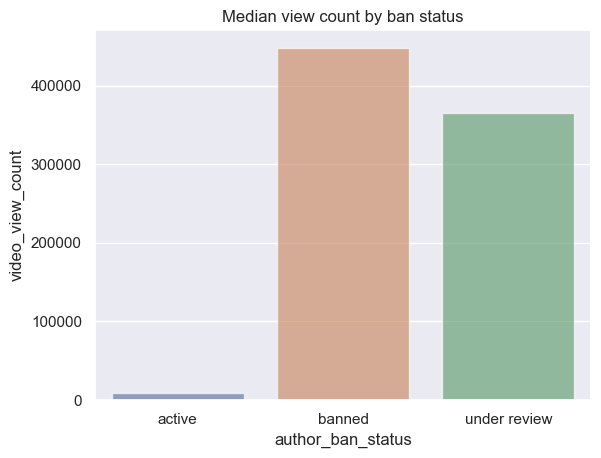

In [ ]:
(
    sns.barplot(
        data=ban_status_counts,
        x="author_ban_status",
        y="video_view_count",
        hue="author_ban_status",
        alpha=0.65,
    ),
    plt.title("Median view count by ban status"),
);

The median view counts for non-active authors are many times greater than the median view count for active authors. Since you know that non-active authors are more likely to post claims, and that videos by non-active authors get far more views on aggregate than videos by active authors, then `video_view_count` might be a good indicator of claim status.

In [ ]:
df.groupby("claim_status")["video_view_count"].median()

claim_status
claim      501555.0
opinion      4953.0
Name: video_view_count, dtype: float64

### Total views by claim status

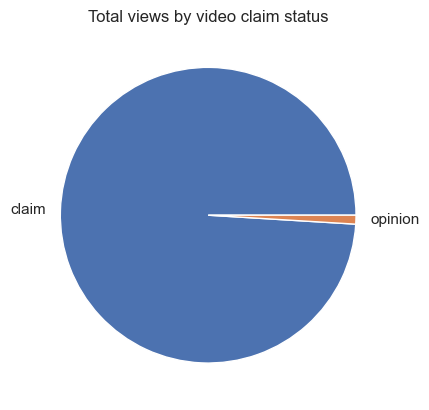

In [ ]:
(
    plt.pie(
        df.groupby("claim_status")["video_view_count"].sum(),
        labels=["claim", "opinion"],
    ),
    plt.title("Total views by video claim status"),
);

The overall view count is dominated by claim videos even though there are roughly the same number of each video in the dataset.

### Outliers:

In [ ]:
for i in [
    "video_view_count",
    "video_like_count",
    "video_share_count",
    "video_download_count",
    "video_comment_count",
]:
    iqr = df[i].quantile(0.75) - df[i].quantile(0.25)
    med = df[i].median()
    thres = med + 1.5 * iqr
    no_outliers = df[df[i] > thres].shape[0]

    print(f"no. of outliers in {i}: {no_outliers}")

no. of outliers in video_view_count: 2343
no. of outliers in video_like_count: 3468
no. of outliers in video_share_count: 3732
no. of outliers in video_download_count: 3733
no. of outliers in video_comment_count: 3882


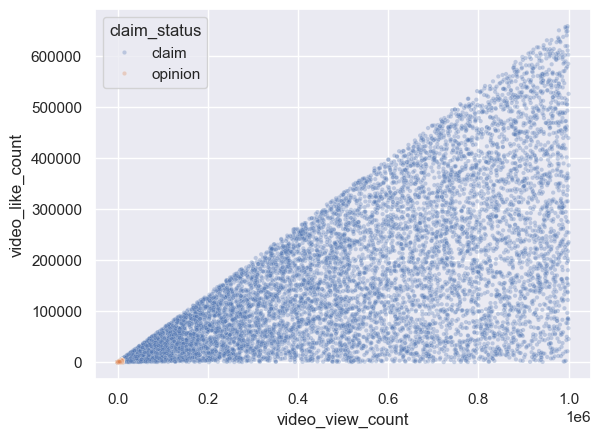

In [ ]:
sns.scatterplot(
    x=df["video_view_count"],
    y=df["video_like_count"],
    hue=df["claim_status"],
    s=10,
    alpha=0.3,
);

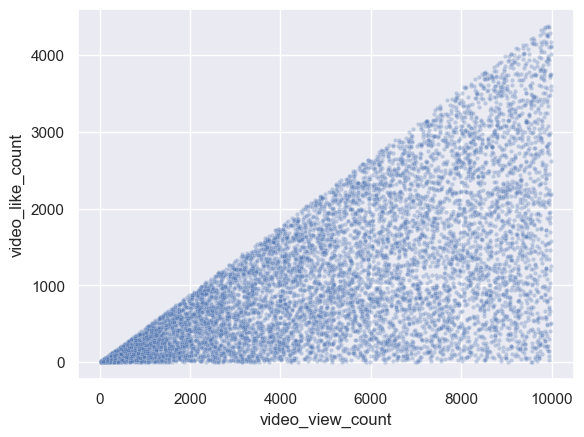

In [ ]:
opinion = df[df["claim_status"] == "opinion"]
sns.scatterplot(
    x=opinion["video_view_count"],
    y=opinion["video_like_count"],
    s=10,
    alpha=0.3,
);